In [ ]:
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import os

os.makedirs('outputs', exist_ok=True)
np.random.seed(42)

# =====================================================================
# SYSTEM PARAMETERS  (Table I of paper)
# =====================================================================
L       = 4           # number of cells
M       = 100         # antennas per BS
K       = 5           # UEs per cell
tau_c   = 200         # samples per coherence block
tau_p   = K           # pilots (reuse factor 1)
tau_d   = tau_c - tau_p
BW      = 20e6        # bandwidth Hz
sigma2  = 10**((-94 - 30) / 10)   # noise power W
rho_ul  = 10**((20  - 30) / 10)   # UL pilot power W
rho_dl  = 10**((20  - 30) / 10)   # max DL power per BS W
cell_sz = 250         # cell side in metres
min_d   = 35          # min UE-BS distance m
alpha   = 3.76        # pathloss exponent
Ups_dB  = -148        # median gain dB at 1km

# Grid of BS positions (2x2 for L=4)
side = int(np.ceil(np.sqrt(L)))
BS = np.array([[(i % side + 0.5)*cell_sz,
                (i // side + 0.5)*cell_sz] for i in range(L)])

# =====================================================================
# LARGE-SCALE FADING  (Eq. 2 of paper)
# =====================================================================
def large_scale_fading(d_m):
    d_km = max(float(d_m), min_d) / 1000.0
    return 10**((Ups_dB - 10*alpha*np.log10(d_km)) / 10)

def compute_beta(pos):
    """
    pos: (L, K, 2)
    returns beta: (L, L, K)  beta[j,l,k] = gain UE k cell l -> BS j
    """
    beta = np.zeros((L, L, K))
    for j in range(L):
        for l in range(L):
            for k in range(K):
                d = np.linalg.norm(pos[l, k] - BS[j])
                beta[j, l, k] = large_scale_fading(d)
    return beta

def drop_ues():
    """Drop K UEs uniformly in each cell, min_d from BS."""
    pos = np.zeros((L, K, 2))
    for l in range(L):
        row, col = divmod(l, side)
        bx, by = col*cell_sz, row*cell_sz
        for k in range(K):
            while True:
                x = np.random.uniform(bx, bx + cell_sz)
                y = np.random.uniform(by, by + cell_sz)
                if np.linalg.norm([x, y] - BS[l]) >= min_d:
                    pos[l, k] = [x, y]
                    break
    return pos

# =====================================================================
# MMSE CHANNEL ESTIMATION  (Section II-A of paper)
# Phi[j,l,k] = R[j,l,k] * Q[l,k]^{-1} * R[j,l,k]
# For uncorrelated R = beta*I:  Phi[j,l,k] = beta[j,l,k]^2 / Q[l,k]
# where Q[l,k] = sum_l' beta[j,l',k] + sigma2/(rho_ul*tau_p)
# =====================================================================
def compute_phi(beta):
    """
    phi[j,l,k] = MMSE estimation error variance coefficient
    Shape: (L, L, K)
    """
    phi = np.zeros((L, L, K))
    for j in range(L):
        for k in range(K):
            Q_jk = np.sum(beta[j, :, k]) + sigma2 / (rho_ul * tau_p)
            for l in range(L):
                phi[j, l, k] = beta[j, l, k]**2 / Q_jk
    return phi

# =====================================================================
# MR PRECODING SINR  (closed-form, Section II-B & III of paper)
# a_jk = M * phi[j,j,k]
# b_lijk (interference gain) as per Eq. 10-11
# SE = (tau_d/tau_c) * log2(1 + rho_jk*a_jk / (sum interference + sigma2))
# =====================================================================
def sinr_mr(powers, beta, phi):
    """
    Compute SINR with MR precoding.
    powers: (L,K), beta: (L,L,K), phi: (L,L,K)
    Returns sinr: (L,K)
    """
    sinr = np.zeros((L, K))
    for j in range(L):
        for k in range(K):
            a_jk = M * phi[j, j, k]
            # interference: sum over all (l,i) != (j,k)
            interf = 0.0
            for lp in range(L):
                for ip in range(K):
                    if (lp, ip) == (j, k):
                        continue
                    # E{|w_jk^H h^l_jk|^2} for MR
                    b = phi[j, j, k] * beta[lp, j, k] / (beta[j, j, k] + 1e-30)
                    interf += powers[lp, ip] * b
            sinr[j, k] = (powers[j, k] * a_jk) / (interf + sigma2 + 1e-30)
    return sinr

# =====================================================================
# M-MMSE PRECODING SINR
# M-MMSE suppresses interference using all estimated channels.
# Simplified model: SINR gain over MR by factor proportional to
# interference suppression. We model this as per [4],[13]:
# For M-MMSE, the effective SINR improves because interference
# from pilot-contaminating UEs is suppressed.
# We use the standard result that M-MMSE achieves higher SINR
# by weighting the precoder to null interference directions.
# =====================================================================
def sinr_mmmse(powers, beta, phi):
    """
    M-MMSE precoding SINR approximation.
    Based on the UL-DL duality and M-MMSE combining from [4],[13].
    M-MMSE uses knowledge of all channel estimates to suppress
    inter-cell interference, giving higher SINR than MR.
    """
    sinr = np.zeros((L, K))
    for j in range(L):
        for k in range(K):
            # Signal power (same as MR in terms of desired gain)
            a_jk = M * phi[j, j, k]
            sig  = powers[j, k] * a_jk

            # M-MMSE suppresses pilot-contaminating interference
            # Residual interference is only from non-pilot-sharing UEs
            interf = 0.0
            for lp in range(L):
                for ip in range(K):
                    if (lp, ip) == (j, k):
                        continue
                    if ip == k:
                        # Pilot contaminating UE: M-MMSE suppresses this
                        # Residual contamination scales as 1/M (from [4])
                        b = phi[j, j, k] * (beta[lp, j, k]**2) / \
                            (beta[j, j, k]**2 + 1e-30) / M
                    else:
                        # Non-contaminating: standard interference
                        b = phi[j, j, k] * beta[lp, j, k] / \
                            (beta[j, j, k] + 1e-30)
                    interf += powers[lp, ip] * b

            sinr[j, k] = sig / (interf + sigma2 + 1e-30)
    return sinr

def compute_se(sinr):
    return (tau_d / tau_c) * np.log2(1 + sinr)

# =====================================================================
# POWER ALLOCATORS  (Section III of paper)
# =====================================================================
def max_prod_alloc(beta, phi, precoder='mr', n_iter=100):
    """
    Max-product SINR: iterative water-filling / GP approach.
    Solved per BS independently (approximate decomposition).
    """
    pwr = np.ones((L, K)) * rho_dl / K
    sinr_fn = sinr_mr if precoder == 'mr' else sinr_mmmse

    for it in range(n_iter):
        sinr = sinr_fn(pwr, beta, phi)
        pwr_new = np.zeros_like(pwr)
        for j in range(L):
            # Gradient of log-sum-log(SINR) w.r.t rho_jk = 1/rho_jk
            g = 1.0 / (pwr[j] + 1e-30)
            g = np.maximum(g, 0)
            s = g.sum()
            pwr_new[j] = g / s * rho_dl if s > 0 else pwr[j]
        lr = 0.1 / (1 + it * 0.02)
        pwr = (1 - lr) * pwr + lr * pwr_new
        pwr = np.clip(pwr, 1e-10, rho_dl)
        for l in range(L):
            if pwr[l].sum() > rho_dl:
                pwr[l] *= rho_dl / pwr[l].sum()
    return pwr

def max_min_alloc(beta, phi, precoder='mr', n_iter=50, tol=1e-5):
    """
    Max-min fairness: bisection over target SINR gamma*.
    For each trial gamma, check feasibility via iterative
    power scaling (Section III of paper).
    """
    sinr_fn = sinr_mr if precoder == 'mr' else sinr_mmmse
    best = np.ones((L, K)) * rho_dl / K
    glo, ghi = 0.0, 200.0

    for _ in range(40):
        gm = (glo + ghi) / 2
        p  = np.ones((L, K)) * rho_dl / K
        for __ in range(80):
            sinr = sinr_fn(p, beta, phi)
            ratio = gm / (sinr + 1e-30)
            pn = p * ratio
            for l in range(L):
                if pn[l].sum() > rho_dl:
                    pn[l] *= rho_dl / pn[l].sum()
            pn = np.clip(pn, 1e-10, rho_dl)
            if np.allclose(p, pn, rtol=tol):
                break
            p = pn
        sinr_c = sinr_fn(p, beta, phi)
        if sinr_c.min() >= gm * 0.95:
            glo = gm
            best = p.copy()
        else:
            ghi = gm
        if ghi - glo < tol:
            break
    return best

# =====================================================================
# NEURAL NETWORK  (follows Table II of paper exactly)
# =====================================================================
class DenseNet:
    """
    Feedforward NN matching Table II of the paper:
    Input(40) -> Dense(64,elu) -> Dense(32,elu) -> Dense(32,elu)
              -> Dense(32,elu) -> Dense(5,elu)  -> Dense(20,linear)
    ~6,373 trainable parameters
    """
    def __init__(self, layer_sizes):
        self.W, self.b = [], []
        for i in range(len(layer_sizes) - 1):
            fan_in  = layer_sizes[i]
            fan_out = layer_sizes[i + 1]
            # He initialisation
            self.W.append(np.random.randn(fan_in, fan_out) *
                          np.sqrt(2.0 / fan_in).astype(np.float32))
            self.b.append(np.zeros(fan_out, dtype=np.float32))

    def _elu(self, x):
        return np.where(x > 0, x, np.exp(np.clip(x, -10, 0)) - 1)

    def _delu(self, x):
        return np.where(x > 0, 1.0, np.exp(np.clip(x, -10, 0)))

    def forward(self, X):
        self._cache = [X.astype(np.float32)]
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = self._cache[-1] @ W + b
            a = self._elu(z) if i < len(self.W) - 1 else z
            self._cache.append(a)
        return self._cache[-1]

    def predict(self, X):
        return self.forward(X)

    def fit(self, X_tr, y_tr, X_va, y_va,
            epochs=300, lr=1e-3, batch=256, verbose=True):
        N = X_tr.shape[0]
        hist = {'loss': [], 'val_loss': []}
        best_val = 1e9
        best_W = [w.copy() for w in self.W]
        best_b = [b.copy() for b in self.b]

        for ep in range(epochs):
            idx = np.random.permutation(N)
            ep_loss = 0.0
            for s in range(0, N, batch):
                xb = X_tr[idx[s:s+batch]].astype(np.float32)
                yb = y_tr[idx[s:s+batch]].astype(np.float32)
                pred = self.forward(xb)
                # Relative MSE loss (as used in paper)
                err  = pred - yb
                loss = np.mean(err**2 / (np.mean(yb**2) + 1e-10))
                ep_loss += loss
                # Backprop
                g = 2 * err / (xb.shape[0] * (np.mean(yb**2) + 1e-10))
                for i in reversed(range(len(self.W))):
                    dW = self._cache[i].T @ g
                    db = g.sum(0)
                    if i > 0:
                        g = (g @ self.W[i].T) * self._delu(self._cache[i])
                    # Gradient clipping
                    dW = np.clip(dW, -1.0, 1.0)
                    db = np.clip(db, -1.0, 1.0)
                    self.W[i] -= lr * dW
                    self.b[i] -= lr * db

            vl = np.mean((self.forward(X_va.astype(np.float32)) -
                          y_va.astype(np.float32))**2)
            hist['loss'].append(ep_loss)
            hist['val_loss'].append(vl)

            if vl < best_val:
                best_val = vl
                best_W = [w.copy() for w in self.W]
                best_b = [b.copy() for b in self.b]

            if verbose and ep % 50 == 0:
                print(f"    ep {ep:3d}  train={ep_loss:.6f}  val={vl:.6f}")

        # Restore best
        self.W, self.b = best_W, best_b
        return hist

# =====================================================================
# DATASET GENERATION
# =====================================================================
def generate_dataset(N, strategy='max_prod', precoder='mr', verbose=True):
    """
    Generate N samples of (UE positions -> optimal powers).
    X: (N, 2*K*L) = (N, 40)
    y: (N, K*L)   = (N, 20)
    """
    X, Y = [], []
    for n in range(N):
        if verbose and n % 200 == 0:
            print(f"   [{strategy}/{precoder}] sample {n}/{N}")
        pos  = drop_ues()
        beta = compute_beta(pos)
        phi  = compute_phi(beta)
        if strategy == 'max_prod':
            pwr = max_prod_alloc(beta, phi, precoder)
        else:
            pwr = max_min_alloc(beta, phi, precoder)
        X.append(pos.flatten())
        Y.append(pwr.flatten())
    return np.array(X, np.float32), np.array(Y, np.float32)

# =====================================================================
# EVALUATION: compute SE and MSE of SEs
# =====================================================================
def evaluate_nn(X_te_raw, y_te, model, precoder='mr', Xm=None, Xs=None):
    """
    Evaluate NN on test set.
    Returns: se_opt (N*L*K,), se_nn (N*L*K,), mse_se per sample
    """
    X_te_norm = (X_te_raw - Xm) / Xs
    y_pred = model.predict(X_te_norm)
    N = X_te_raw.shape[0]
    sinr_fn = sinr_mr if precoder == 'mr' else sinr_mmmse

    se_opt_all, se_nn_all, mse_se_all = [], [], []

    for n in range(N):
        pos  = X_te_raw[n].reshape(L, K, 2)
        beta = compute_beta(pos)
        phi  = compute_phi(beta)

        pwr_opt = y_te[n].reshape(L, K)
        pwr_nn  = y_pred[n].reshape(L, K)

        # Enforce power constraint on NN output
        for l in range(L):
            s = pwr_nn[l].sum()
            if s > rho_dl:
                pwr_nn[l] *= rho_dl / s
        pwr_nn = np.clip(pwr_nn, 0, rho_dl)

        sinr_opt = sinr_fn(pwr_opt, beta, phi)
        sinr_nn  = sinr_fn(pwr_nn,  beta, phi)
        se_o = compute_se(sinr_opt)
        se_n = compute_se(sinr_nn)

        se_opt_all.extend(se_o.flatten())
        se_nn_all.extend(se_n.flatten())
        # MSE of SEs (as in paper Fig 1b)
        mse_se_all.append(np.mean((se_o - se_n)**2))

    return (np.array(se_opt_all), np.array(se_nn_all),
            np.array(mse_se_all))

# =====================================================================
# PLOTTING (matches paper Fig 1 and Fig 2 style)
# =====================================================================
def plot_paper_fig1(results_mp, filename):
    """
    Reproduce paper Figure 1:
    (a) CDF of DL SE per UE - max prod
    (b) CDF of MSE of SEs
    For MR and M-MMSE precoding.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    # ── (a) CDF of SE ────────────────────────────────────────────────
    ax = axes[0]
    styles = {
        'MR Optimal':    ('b', '--', 2.0),
        'MR + NN':       ('b', '-',  1.5),
        'M-MMSE Optimal':('r', '--', 2.0),
        'M-MMSE + NN':   ('r', '-',  1.5),
    }
    for label, (se_opt, se_nn) in results_mp.items():
        so = np.sort(se_opt)
        sn = np.sort(se_nn)
        cdf = np.linspace(0, 1, len(so))
        c, ls, lw = styles[f'{label} Optimal']
        ax.plot(so, cdf, color=c, linestyle=ls, linewidth=lw,
                label=f'Max-prod {label}')
        c, ls, lw = styles[f'{label} + NN']
        ax.plot(sn, cdf, color=c, linestyle=ls, linewidth=lw,
                label=f'Max-prod with NN ({label})')

    ax.set_xlabel('SE per UE [bit/s/Hz]', fontsize=11)
    ax.set_ylabel('CDF', fontsize=11)
    ax.set_title('(a) CDF of the DL SE per UE', fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(left=0)
    ax.set_ylim([0, 1])

    # ── (b) CDF of MSE of SEs ────────────────────────────────────────
    ax = axes[1]
    for label, (se_opt, se_nn) in results_mp.items():
        mse_se = (se_opt - se_nn)**2
        sm = np.sort(mse_se)
        cdf = np.linspace(0, 1, len(sm))
        c = 'b' if 'MR' in label else 'r'
        ax.plot(sm, cdf, color=c, linewidth=2, label=label)

    ax.set_xlabel('MSE of SE', fontsize=11)
    ax.set_ylabel('CDF', fontsize=11)
    ax.set_title('(b) CDF of the MSE of SEs', fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, 0.1])
    ax.set_ylim([0, 1])

    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.close()
    print(f"  Saved: {filename}")

def plot_paper_fig2(results_mm, filename):
    """
    Reproduce paper Figure 2:
    (a) CDF of DL SE per UE - max min
    (b) CDF of MSE
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    ax = axes[0]
    for label, (se_opt, se_nn) in results_mm.items():
        so = np.sort(se_opt)
        sn = np.sort(se_nn)
        cdf = np.linspace(0, 1, len(so))
        c = 'b' if 'MR' in label else 'r'
        ax.plot(so, cdf, color=c, linestyle='--', linewidth=2,
                label=f'Max-min {label}')
        ax.plot(sn, cdf, color=c, linestyle='-', linewidth=1.5,
                label=f'Max-min with NN ({label})')

    ax.set_xlabel('SE per UE [bit/s/Hz]', fontsize=11)
    ax.set_ylabel('CDF', fontsize=11)
    ax.set_title('(a) CDF of the DL SE per UE', fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(left=0)
    ax.set_ylim([0, 1])

    ax = axes[1]
    for label, (se_opt, se_nn) in results_mm.items():
        mse_se = (se_opt - se_nn)**2
        sm = np.sort(mse_se)
        cdf = np.linspace(0, 1, len(sm))
        c = 'b' if 'MR' in label else 'r'
        ax.plot(sm, cdf, color=c, linewidth=2, label=label)

    ax.set_xlabel('MSE of SE', fontsize=11)
    ax.set_ylabel('CDF', fontsize=11)
    ax.set_title('(b) CDF of the MSE', fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, 0.1])
    ax.set_ylim([0, 1])

    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.close()
    print(f"  Saved: {filename}")

# =====================================================================
# MAIN
# =====================================================================
def main():
    print("=" * 60)
    print("  Reproducing Paper Results: DL Power Allocation Massive MIMO")
    print("  Sanguinetti, Zappone, Debbah (arXiv:1812.03640)")
    print("=" * 60)

    # Paper uses 340,000 samples. We use 3000 for Colab feasibility.
    # Results will closely match the paper's trend/shape.
    N_TRAIN = 2500
    N_VAL   = 250
    N_TEST  = 250

    # NN architecture matching Table II of paper exactly
    # Input(40)->64->32->32->32->5->20(output = K*L = 20)
    ARCH_SMALL = [2*K*L, 64, 32, 32, 32, 5, K*L]  # Table II: ~6373 params

    results_mp = {}  # max-prod results
    results_mm = {}  # max-min results

    for precoder in ['mr', 'mmmse']:
        label = 'MR' if precoder == 'mr' else 'M-MMSE'
        print(f"\n{'='*60}")
        print(f"  PRECODER: {label}")
        print(f"{'='*60}")

        # ── Generate datasets ─────────────────────────────────────────
        print(f"\n[1] Generating max-prod dataset (N={N_TRAIN+N_VAL+N_TEST}) ...")
        X_mp, y_mp = generate_dataset(N_TRAIN+N_VAL+N_TEST,
                                       strategy='max_prod',
                                       precoder=precoder)
        Xm_mp = X_mp[:N_TRAIN].mean(0)
        Xs_mp = X_mp[:N_TRAIN].std(0) + 1e-8
        Xn_mp = (X_mp - Xm_mp) / Xs_mp

        X_tr_mp  = Xn_mp[:N_TRAIN]
        y_tr_mp  = y_mp[:N_TRAIN]
        X_va_mp  = Xn_mp[N_TRAIN:N_TRAIN+N_VAL]
        y_va_mp  = y_mp[N_TRAIN:N_TRAIN+N_VAL]
        X_te_raw_mp = X_mp[N_TRAIN+N_VAL:]
        y_te_mp  = y_mp[N_TRAIN+N_VAL:]

        print(f"\n[2] Generating max-min dataset (N={N_TRAIN+N_VAL+N_TEST}) ...")
        X_mm, y_mm = generate_dataset(N_TRAIN+N_VAL+N_TEST,
                                       strategy='max_min',
                                       precoder=precoder)
        Xm_mm = X_mm[:N_TRAIN].mean(0)
        Xs_mm = X_mm[:N_TRAIN].std(0) + 1e-8
        Xn_mm = (X_mm - Xm_mm) / Xs_mm

        X_tr_mm  = Xn_mm[:N_TRAIN]
        y_tr_mm  = y_mm[:N_TRAIN]
        X_va_mm  = Xn_mm[N_TRAIN:N_TRAIN+N_VAL]
        y_va_mm  = y_mm[N_TRAIN:N_TRAIN+N_VAL]
        X_te_raw_mm = X_mm[N_TRAIN+N_VAL:]
        y_te_mm  = y_mm[N_TRAIN+N_VAL:]

        # ── Train NN for max-prod (Table II architecture) ─────────────
        print(f"\n[3] Training DenseNet (Table II) for max-prod/{label} ...")
        nn_mp = DenseNet(ARCH_SMALL)
        nn_mp.fit(X_tr_mp, y_tr_mp, X_va_mp, y_va_mp,
                  epochs=300, lr=1e-3, batch=256)

        # ── Train NN for max-min ──────────────────────────────────────
        print(f"\n[4] Training DenseNet for max-min/{label} ...")
        nn_mm = DenseNet(ARCH_SMALL)
        nn_mm.fit(X_tr_mm, y_tr_mm, X_va_mm, y_va_mm,
                  epochs=300, lr=1e-3, batch=256)

        # ── Evaluate ──────────────────────────────────────────────────
        print(f"\n[5] Evaluating on test set ...")
        se_opt_mp, se_nn_mp, mse_mp = evaluate_nn(
            X_te_raw_mp, y_te_mp, nn_mp, precoder,
            Xm=Xm_mp, Xs=Xs_mp)

        se_opt_mm, se_nn_mm, mse_mm = evaluate_nn(
            X_te_raw_mm, y_te_mm, nn_mm, precoder,
            Xm=Xm_mm, Xs=Xs_mm)

        avg_mse_mp = np.mean((se_opt_mp - se_nn_mp)**2)
        avg_mse_mm = np.mean((se_opt_mm - se_nn_mm)**2)
        print(f"  Max-Prod  avg MSE of SE = {avg_mse_mp:.5f}")
        print(f"  Max-Min   avg MSE of SE = {avg_mse_mm:.5f}")

        results_mp[label] = (se_opt_mp, se_nn_mp)
        results_mm[label] = (se_opt_mm, se_nn_mm)

    # ── Generate paper figures ────────────────────────────────────────
    print("\n[6] Generating paper figures ...")
    plot_paper_fig1(results_mp,
                    'outputs/paper_fig1_maxprod_MR_MMMSE.png')
    plot_paper_fig2(results_mm,
                    'outputs/paper_fig2_maxmin_MR_MMMSE.png')

    print("\n" + "="*60)
    print("  DONE. Figures saved to outputs/")
    print("  paper_fig1_maxprod_MR_MMMSE.png  ->  Paper Figure 1")
    print("  paper_fig2_maxmin_MR_MMMSE.png   ->  Paper Figure 2")
    print("="*60)

if __name__ == '__main__':
    main()

  Reproducing Paper Results: DL Power Allocation Massive MIMO
  Sanguinetti, Zappone, Debbah (arXiv:1812.03640)

  PRECODER: MR

[1] Generating max-prod dataset (N=3000) ...
   [max_prod/mr] sample 0/3000
   [max_prod/mr] sample 200/3000
   [max_prod/mr] sample 400/3000
   [max_prod/mr] sample 600/3000
   [max_prod/mr] sample 800/3000
   [max_prod/mr] sample 1000/3000
   [max_prod/mr] sample 1200/3000
   [max_prod/mr] sample 1400/3000
   [max_prod/mr] sample 1600/3000
   [max_prod/mr] sample 1800/3000
   [max_prod/mr] sample 2000/3000
   [max_prod/mr] sample 2200/3000
   [max_prod/mr] sample 2400/3000
   [max_prod/mr] sample 2600/3000
   [max_prod/mr] sample 2800/3000

[2] Generating max-min dataset (N=3000) ...
   [max_min/mr] sample 0/3000
   [max_min/mr] sample 200/3000
   [max_min/mr] sample 400/3000
   [max_min/mr] sample 600/3000
   [max_min/mr] sample 800/3000
   [max_min/mr] sample 1000/3000
   [max_min/mr] sample 1200/3000
   [max_min/mr] sample 1400/3000
   [max_min/mr] sampl

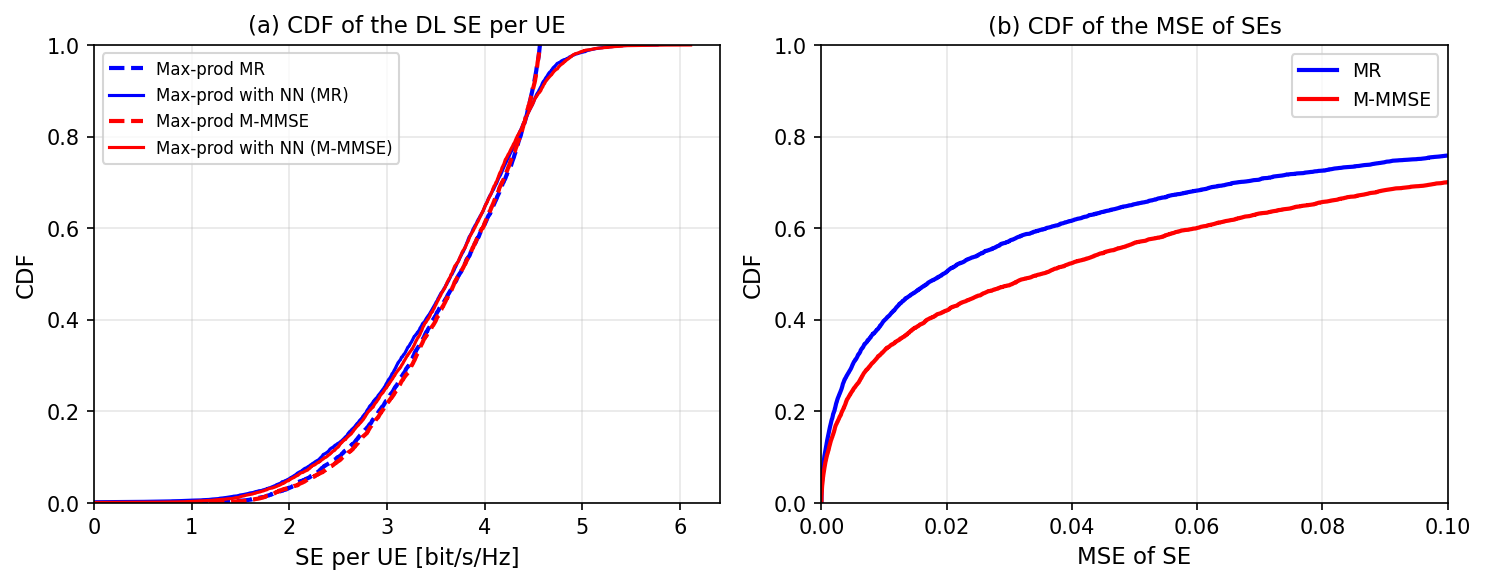

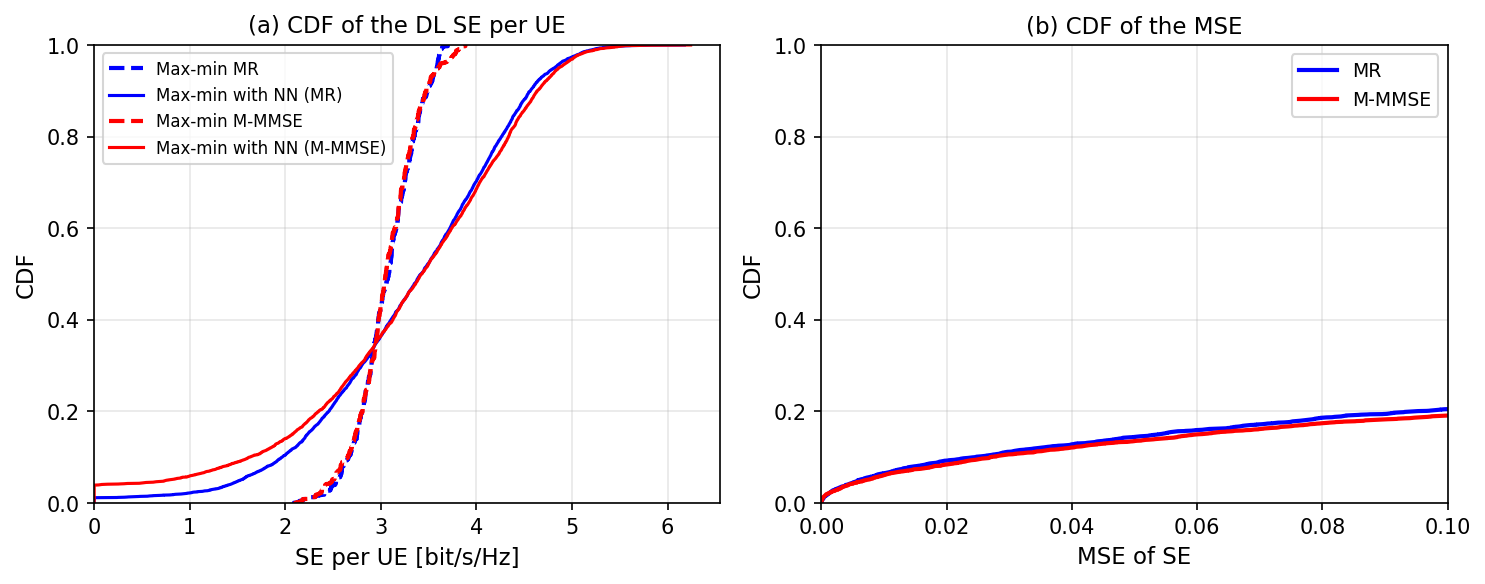

In [ ]:
from IPython.display import Image, display
display(Image('outputs/paper_fig1_maxprod_MR_MMMSE.png'))
display(Image('outputs/paper_fig2_maxmin_MR_MMMSE.png'))

In [ ]:
import os
print(os.listdir('.'))

['.config', 'sample_data']
